# PetFinder.my: прогноз швидкості усиновлення тварини за фото, описом і табличними ознаками

Фінальний проєкт курсу «Deep Learning for Computer Vision and NLP» (GoIT). Автор: Фарід Джафарлі.

Задача: за оголошенням про тварину (фото, текстовий опис, табличні характеристики) передбачити `AdoptionSpeed`, тобто як швидко її заберуть. Ціль порядкова (чим більше число, тим довше тварина чекає на господаря), тому в змаганні використовують метрику quadratic weighted kappa (QWK). Вона штрафує тим сильніше, чим далі прогноз від правильного класу, і враховує збіги, які можна отримати випадково.

Мій підхід коротко:

1. Знаходжу файли змагання й перевіряю колонки. Набір даних для курсу «спеціально адаптований», тому код не покладається на жорсткі назви файлів і колонок: він сам їх шукає і пояснює, чого бракує.
2. Будую ознаки з трьох джерел:
   - табличні колонки (якщо вони є) і прості статистики тексту;
   - текст: TF-IDF слів і символьних n-грам, стиснений TruncatedSVD, і ембединги речень з попередньо навченого трансформера;
   - зображення: ембединги попередньо навченої CNN (EfficientNet-B0, ваги ImageNet), усереднені по фото тварини.
3. Навчаю LightGBM як регресію на порядковій цілі. Неперервний прогноз перетворюю на класи порогами, які підбираю під QWK на out-of-fold прогнозах (OptimizedRounder).
4. Оцінюю якість 5-fold крос-валідацією (StratifiedKFold, або StratifiedGroupKFold за `RescuerID`, якщо така колонка є).
5. Перенавчаю модель на всіх даних train, роблю прогноз для тестового (валідаційного) набору й записую `submission.csv` з заголовком `PetID,AdoptionSpeed`.

AutoML-бібліотек (AutoGluon, H2O AutoML, auto-sklearn, TPOT, FLAML, PyCaret тощо) я не використовую. Optuna (за замовчуванням вимкнена) лише перебирає кілька гіперпараметрів LightGBM у діапазонах, які я задав сам.

Розділи ноутбука: 0. Налаштування; 1. Дані; 2. EDA; 3. Ознаки; 4. Модель і валідація; 5. Фінальне навчання й сабміт; 6. Результати; 7. Як відтворити.

## 0. Налаштування

Усе, що може знадобитися змінити під дані змагання, зібране в одній клітинці `CONFIG` нижче.

- Дані ноутбук шукає сам: спершу в `/kaggle/input/*` (на Kaggle), потім у локальній папці `data/`. Train шукаю як таблицю з `PetID` і `AdoptionSpeed`, тестовий набір як таблицю з `PetID` і назвою `test` / `valid` / `val`, а `sample_submission` просто за назвою. Якщо автопошук вибрав не ті файли, досить вписати шляхи в `TRAIN_CSV` / `TEST_CSV`.
- Фото шукаю в усій папці даних і зіставляю з `PetID` за трьома схемами: `<PetID>-<n>.jpg` (як в оригінальному змаганні), `<PetID>.jpg` і папка на тварину `<PetID>/*.jpg`.
- Якщо даних змагання немає зовсім, ноутбук переходить у проксі-режим: бере табличний датасет PetFinder з курсу ML (11 537 тварин, без фото й без `PetID`) і відкладає 20 % рядків як «псевдо-тест». Цей режим потрібен лише для перевірки коду. Сабміт у ньому називається `submission_proxy.csv`, щоб його не можна було сплутати зі справжнім.

Запуск на Kaggle: `Add Input` → дані змагання; `Settings` → `Accelerator: GPU T4 x2` (або P100) і `Internet: On` (потрібна верифікація телефону). Інтернет потрібен, щоб завантажити ваги EfficientNet і текстову модель. Якщо його вимкнено, ваги треба додати як Kaggle Dataset і вказати шляхи в `IMAGE_WEIGHTS_PATH` і `TEXT_MODEL` (докладніше в README).

In [1]:
# ================================ CONFIG ================================
SEED = 42

# --- Де шукати дані ---
DATA_ROOT = None                 # None = автопошук: спершу /kaggle/input/*, потім LOCAL_DATA_DIRS
LOCAL_DATA_DIRS = ['data', '../data']
TRAIN_CSV = None                 # явні шляхи, якщо автопошук вибрав не ті файли
TEST_CSV = None                  # набір, для якого робимо сабміт (test / valid)
SAMPLE_SUB_CSV = None

# Проксі-дані для локальної перевірки коду: таблиця PetFinder з курсу ML (без фото)
ALLOW_PROXY = True
PROXY_CSV = '../../machine-learning-fundamentals/datasets/mod_04_topic_08_petfinder_data.csv.gz'
PROXY_TEST_SHARE = 0.2

# --- Колонки (якщо назва інша, ноутбук спробує відомі варіанти й підкаже) ---
ID_COL = 'PetID'
TARGET_COL = 'AdoptionSpeed'
TEXT_COL = 'Description'
GROUP_COL = 'RescuerID'          # якщо колонки немає -> звичайний StratifiedKFold
SUB_COLUMNS = ('PetID', 'AdoptionSpeed')   # заголовок сабміту: рівно такий
CATEGORICAL_HINTS = ['Type', 'Breed1', 'Breed2', 'Gender', 'Color1', 'Color2', 'Color3', 'State',
                     'MaturitySize', 'FurLength', 'Vaccinated', 'Dewormed', 'Sterilized', 'Health']

# --- Зображення ---
USE_IMAGES = True                # у режимі змагання без знайдених фото ноутбук зупиниться з поясненням
TRAIN_IMAGE_DIR = None           # None = шукати фото в усій папці даних
TEST_IMAGE_DIR = None
IMAGE_NAME_REGEX = r'^(?P<pet_id>.+?)-(?P<n>\d+)\.(?:jpe?g|png|webp|bmp)$'   # <PetID>-<n>.jpg
MAX_IMAGES_PER_PET = 5           # беру перші N фото тварини (на CPU краще 1-2)
IMAGE_BACKBONE = 'efficientnet_b0'   # 'efficientnet_b0' | 'densenet121' | 'resnet50' | 'hf:<id або шлях>' (CLIP / SigLIP)
IMAGE_WEIGHTS_PATH = None        # .pth з вагами torchvision, якщо на Kaggle вимкнено інтернет
IMG_SIZE = 224
IMG_BATCH_SIZE = 64
IMG_PCA_DIM = 32                 # стискаю ембединг фото до 32 компонент

# --- Текст ---
TFIDF_WORD_SVD = 32
TFIDF_CHAR_SVD = 32
USE_TEXT_EMB = True
TEXT_MODEL = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'   # id на Hugging Face або шлях до Kaggle Dataset
TEXT_MAX_LEN = 256
TEXT_BATCH_SIZE = 64
TEXT_PCA_DIM = 32

USE_JSON_FEATURES = True         # *_sentiment / *_metadata JSON, як в оригінальному змаганні (якщо вони є)

# --- Модель і валідація ---
MODEL_LIB = 'auto'               # 'auto' (LightGBM, якщо встановлено) | 'lightgbm' | 'sklearn'
N_FOLDS = 5
MODEL_SEEDS = [42, 7, 2026]      # усереднюю моделі з кількома seed-ами
N_THREADS = 4                    # фіксую кількість потоків: так LightGBM дає ті самі числа при повторі
LGB_PARAMS = dict(objective='regression', learning_rate=0.02, n_estimators=5000, num_leaves=31,
                  min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                  reg_alpha=0.1, reg_lambda=1.0, cat_smooth=20, min_data_per_group=50, max_cat_to_onehot=8)
EARLY_STOPPING = 200
HGB_PARAMS = dict(learning_rate=0.03, max_iter=3000, max_leaf_nodes=31, min_samples_leaf=30,
                  l2_regularization=1.0, early_stopping=True, validation_fraction=0.1, n_iter_no_change=100)
USE_OPTUNA = False
OPTUNA_TRIALS = 20
TUNED_PARAMS = None              # dict з найкращими параметрами Optuna -> фінальний запуск уже без Optuna
RUN_ABLATION = True              # внесок кожної групи ознак (швидкий режим, 1 seed)

# --- Фінальний прогноз ---
FINAL_PREDICTION = 'blend'       # 'full' (модель на всьому train) | 'folds' (середнє моделей фолдів) | 'blend' (їх середнє)
FULL_FIT_ITER_MULT = 1.15        # дерев для моделі на всьому train = середнє з фолдів x 1.15
ROUNDING = 'optimized'           # 'optimized' (пороги з OOF) | 'distribution' (розподіл класів як у train)
OUTPUT_DIR = None                # None = /kaggle/working на Kaggle, інакше ./outputs
EXPECTED_SUBMISSION_SHA256 = None   # SHA-256 поданого файлу, щоб перевірити, що ноутбук відтворює саме його

In [2]:
import hashlib
import inspect
import json
import os
import platform
import random
import re
import sys
import time
from pathlib import Path

for k, v in {'HF_HUB_VERBOSITY': 'error', 'HF_HUB_DISABLE_PROGRESS_BARS': '1', 'TRANSFORMERS_VERBOSITY': 'error',
             'TOKENIZERS_PARALLELISM': 'false'}.items():
    os.environ.setdefault(k, v)                # тихіший вивід Hugging Face (без прогрес-барів і попереджень)

# LightGBM імпортую ДО torch. На macOS torch, LightGBM і scikit-learn мають різні копії libomp (OpenMP),
# і якщо torch першим запустить свої CPU-потоки, наступне навчання LightGBM падає з segfault.
try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False
import torch
if platform.system() == 'Darwin':
    torch.set_num_threads(1)     # та сама причина; важкі обчислення на Mac однаково йдуть на GPU (MPS)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import cohen_kappa_score, mean_squared_error
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split

T_START = time.time()
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif getattr(torch.backends, 'mps', None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
# DataLoader з кількома процесами: на Linux (Kaggle) так, у Jupyter на macOS / Windows ні
NUM_WORKERS = 0 if platform.system() in ('Darwin', 'Windows') else min(4, os.cpu_count() or 1)

if MODEL_LIB == 'lightgbm' and not HAS_LGB:
    raise ImportError('MODEL_LIB = "lightgbm", але lightgbm не встановлено (pip install lightgbm).')
USE_LGB = HAS_LGB and MODEL_LIB in ('auto', 'lightgbm')
# LightGBM >= 4.7 приймає валідаційні дані як eval_X / eval_y, старші версії як eval_set
LGB_EVAL_XY = USE_LGB and 'eval_X' in inspect.signature(lgb.LGBMRegressor.fit).parameters

ON_KAGGLE = Path('/kaggle/input').exists()
OUT = Path(OUTPUT_DIR) if OUTPUT_DIR else (Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs'))
CACHE = OUT / 'cache'
CACHE.mkdir(parents=True, exist_ok=True)

print(f'Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | '
      f'scikit-learn {sklearn.__version__} | torch {torch.__version__}')
print('Модель:', f'LightGBM {lgb.__version__}' if USE_LGB else 'sklearn HistGradientBoostingRegressor')
print('Пристрій для нейромереж:', DEVICE, '| Kaggle:', ON_KAGGLE, '| вихідна папка:', OUT)

Python 3.12.3 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.0
Модель: LightGBM 4.7.0
Пристрій для нейромереж: mps | Kaggle: False | вихідна папка: outputs


## 1. Дані

Спершу знаходжу таблиці. Train визначаю як файл, у якому є і `PetID`, і ціль, а тестовий набір як файл з `PetID`, у назві якого є `test`, `valid` чи `val`. Якщо таких кандидатів кілька, а є `sample_submission`, беру той, чиї `PetID` збігаються з ним. Потім перевіряю колонки й ціль: якщо чогось бракує, ноутбук зупиняється й друкує, що саме знайшов.

У LMS ціль описана як 1-4, а в оригінальному змаганні вона 0-4. Тому набір класів беру з самих даних (`CLASSES`), а не задаю руками.

In [3]:
ID_ALTS = ('PetID', 'pet_id', 'petid', 'id')
TARGET_ALTS = ('AdoptionSpeed', 'adoption_speed', 'target', 'label')
TEXT_ALTS = ('Description', 'description', 'desc', 'text')
GROUP_ALTS = ('RescuerID', 'rescuer_id')


def pick_col(columns, preferred, alternatives=()):
    """Назва колонки без урахування регістру: спершу preferred, потім альтернативи."""
    lookup = {str(c).lower(): c for c in columns}
    for name in (preferred, *alternatives):
        if name is not None and str(name).lower() in lookup:
            return lookup[str(name).lower()]
    return None


def read_table(path, nrows=None):
    path = Path(path)
    if path.name.lower().endswith('.parquet'):
        df = pd.read_parquet(path)
        return df if nrows is None else df.head(nrows)
    return pd.read_csv(path, nrows=nrows)


def list_tables(root):
    found = []
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = sorted(d for d in dirnames if not d.startswith('.'))
        found += [Path(dirpath) / f for f in sorted(filenames) if f.lower().endswith(('.csv', '.csv.gz', '.parquet'))]
    return found


def find_competition_tables(root):
    """Шукає train / test / sample_submission у папці root за назвами файлів і колонками."""
    tables = []
    for path in list_tables(root):
        try:
            cols = list(read_table(path, nrows=5).columns)
        except Exception:
            continue
        tables.append({'path': path, 'name': path.name.lower(), 'cols': cols})

    def has(t, preferred, alternatives):
        return pick_col(t['cols'], preferred, alternatives) is not None

    def is_sample(t):
        return 'sample' in t['name'] or 'submission' in t['name']

    trains = [t for t in tables if not is_sample(t) and has(t, ID_COL, ID_ALTS) and has(t, TARGET_COL, TARGET_ALTS)]
    trains.sort(key=lambda t: ('train' not in t['name'], len(t['path'].parts), t['name']))
    if not trains:
        return None
    train = trains[0]

    def test_rank(t):
        n = t['name']
        kind = 0 if 'test' in n else 1 if re.search(r'valid|(^|[^a-z])val([^a-z]|$)', n) else 2
        return (kind, has(t, TARGET_COL, TARGET_ALTS), len(t['path'].parts), n)

    tests = sorted([t for t in tables if t is not train and not is_sample(t) and 'train' not in t['name']
                    and has(t, ID_COL, ID_ALTS)], key=test_rank)
    samples = [t for t in tables if is_sample(t)]
    sample = samples[0] if samples else None
    if sample is not None and len(tests) > 1:
        sample_ids = set(read_table(sample['path'])[pick_col(sample['cols'], ID_COL, ID_ALTS)].astype(str))

        def overlap(t):
            ids = read_table(t['path'])[pick_col(t['cols'], ID_COL, ID_ALTS)].astype(str)
            return ids.isin(sample_ids).mean()

        tests.sort(key=lambda t: -overlap(t))      # стабільне сортування: при рівності лишається порядок за назвою
    if not tests:
        return None
    return {'train': train['path'], 'test': tests[0]['path'], 'sample': sample['path'] if sample else None}


def candidate_roots():
    if DATA_ROOT:
        return [Path(DATA_ROOT)]
    roots = []
    if ON_KAGGLE:
        roots += sorted(p for p in Path('/kaggle/input').iterdir() if p.is_dir())
    roots += [Path(p) for p in LOCAL_DATA_DIRS if Path(p).is_dir()]
    return roots


MODE, DATA_DIR, files, sample_df, proxy_truth = None, None, None, None, None
if TRAIN_CSV and TEST_CSV:
    files = {'train': Path(TRAIN_CSV), 'test': Path(TEST_CSV), 'sample': Path(SAMPLE_SUB_CSV) if SAMPLE_SUB_CSV else None}
    DATA_DIR = Path(DATA_ROOT) if DATA_ROOT else Path(TRAIN_CSV).parent
else:
    for root in candidate_roots():
        files = find_competition_tables(root)
        if files:
            DATA_DIR = root
            break

if files:
    MODE = 'competition'
    train_df = read_table(files['train'])
    test_df = read_table(files['test'])
    sample_df = read_table(files['sample']) if files['sample'] else None
    print('Режим: ЗМАГАННЯ. Папка даних:', DATA_DIR)
    for k, v in files.items():
        print(f'  {k:>6}: {v}')
elif ALLOW_PROXY and Path(PROXY_CSV).exists():
    MODE = 'proxy'
    proxy = pd.read_csv(PROXY_CSV)
    proxy.insert(0, ID_COL, [f'proxy{i:05d}' for i in range(len(proxy))])
    train_df, test_df = train_test_split(proxy, test_size=PROXY_TEST_SHARE, stratify=proxy[TARGET_COL], random_state=SEED)
    train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
    proxy_truth = test_df[[ID_COL, TARGET_COL]].copy()        # мітки псевдо-тесту потрібні лише для перевірки в розділі 6
    test_df = test_df.drop(columns=[TARGET_COL])
    print('=' * 88)
    print('Режим: ПРОКСІ. Даних змагання не знайдено -> беру таблицю PetFinder з курсу ML (без фото).')
    print(f'Train {len(train_df)} / псевдо-тест {len(test_df)} рядків. Результати - лише для перевірки коду.')
    print('=' * 88)
else:
    raise FileNotFoundError(
        'Не знайшов даних змагання. На Kaggle: праворуч "Add Input" -> Competitions -> своє змагання. '
        'Локально: розпакуйте архів змагання в папку data/ або вкажіть DATA_ROOT / TRAIN_CSV / TEST_CSV у CONFIG.')

# --- колонки ---
ID = pick_col(train_df.columns, ID_COL, ID_ALTS)
TGT = pick_col(train_df.columns, TARGET_COL, TARGET_ALTS)
TXT = pick_col(train_df.columns, TEXT_COL, TEXT_ALTS)
problems = []
for role, col, pref, alts in [('ID', ID, ID_COL, ID_ALTS), ('текст', TXT, TEXT_COL, TEXT_ALTS)]:
    if col is None:
        problems.append(f'У train немає колонки "{role}" ({pref}).')
    else:
        test_col = pick_col(test_df.columns, pref, alts)
        if test_col is None:
            problems.append(f'У test немає колонки "{role}" ({pref}).')
        elif test_col != col:
            test_df = test_df.rename(columns={test_col: col})
if TGT is None:
    problems.append(f'У train немає цілі ({TARGET_COL}).')
if problems:
    raise ValueError('\n'.join(problems) + f'\ntrain: {list(train_df.columns)}\ntest: {list(test_df.columns)}\n'
                     'Виправте ID_COL / TARGET_COL / TEXT_COL у CONFIG.')
GRP = pick_col(train_df.columns, GROUP_COL, GROUP_ALTS) if GROUP_COL else None

if TGT in test_df.columns:                                   # у тесті ціль може бути порожньою колонкою
    test_df = test_df.drop(columns=[TGT])
n_missing_target = int(train_df[TGT].isna().sum())
if n_missing_target:
    print(f'Увага: {n_missing_target} рядків train без цілі - прибираю.')
    train_df = train_df[train_df[TGT].notna()].reset_index(drop=True)
target_values = pd.to_numeric(train_df[TGT], errors='raise')
if not np.allclose(target_values, np.round(target_values)):
    raise ValueError(f'Ціль {TGT} не цілочисельна - перевірте TARGET_COL.')
train_df[TGT] = np.round(target_values).astype(int)
CLASSES = np.sort(train_df[TGT].unique())

for df in (train_df, test_df):
    df[ID] = df[ID].astype(str)
    df[TXT] = df[TXT].fillna('').astype(str)
for name, df in (('train', train_df), ('test', test_df)):
    if df[ID].duplicated().any():
        raise ValueError(f'У {name} є повтори {ID}: {df[ID][df[ID].duplicated()].head().tolist()}')
overlap_ids = set(train_df[ID]) & set(test_df[ID])
if overlap_ids:
    print(f'Увага: {len(overlap_ids)} {ID} є і в train, і в test.')
if sample_df is not None:
    sample_id_col = pick_col(sample_df.columns, SUB_COLUMNS[0], ID_ALTS)
    sample_df[sample_id_col] = sample_df[sample_id_col].astype(str)
    if set(sample_df[sample_id_col]) != set(test_df[ID]):
        print('Увага: PetID у sample_submission і в тестовому файлі не збігаються повністю - перевірте TEST_CSV.')

print(f'\ntrain: {train_df.shape}, test: {test_df.shape}')
print(f'ID = {ID!r}, ціль = {TGT!r}, текст = {TXT!r}, група для CV = {GRP!r}')
print('Класи цілі:', CLASSES.tolist())
print('Колонки train:', list(train_df.columns))

Режим: ПРОКСІ. Даних змагання не знайдено -> беру таблицю PetFinder з курсу ML (без фото).
Train 9229 / псевдо-тест 2308 рядків. Результати - лише для перевірки коду.

train: (9229, 16), test: (2308, 15)
ID = 'PetID', ціль = 'AdoptionSpeed', текст = 'Description', група для CV = None
Класи цілі: [0, 1, 2, 3, 4]
Колонки train: ['PetID', 'Type', 'Age', 'Breed1', 'Gender', 'Color1', 'Color2', 'MaturitySize', 'FurLength', 'Vaccinated', 'Sterilized', 'Health', 'Fee', 'Description', 'PhotoAmt', 'AdoptionSpeed']


### 1.1. Індекс фото

Проходжу папку даних один раз і для кожного `PetID` збираю список його фото, відсортований за номером (головне фото оголошення: `<PetID>-1.jpg`). Файл вважаю фото тварини, якщо його ім'я відповідає `IMAGE_NAME_REGEX` або якщо назва файлу чи папки збігається з `PetID`. У режимі змагання, якщо не знайдено жодного фото, ноутбук зупиняється: за умовами курсу модель має використовувати і фото, і текст.

In [4]:
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')
IMAGE_RE = re.compile(IMAGE_NAME_REGEX, re.IGNORECASE)


def build_image_index(roots, known_ids):
    """PetID -> список шляхів до фото (за номером фото). Схеми: PetID-N.jpg, PetID.jpg, PetID/*.jpg."""
    index, n_files, n_unmatched = {}, 0, 0
    for root in roots:
        for dirpath, dirnames, filenames in os.walk(root):
            dirnames[:] = sorted(d for d in dirnames if not d.startswith('.'))
            parent = Path(dirpath).name
            for f in sorted(filenames):
                if not f.lower().endswith(IMG_EXTS):
                    continue
                n_files += 1
                stem = Path(f).stem
                m = IMAGE_RE.match(f)
                if m and m.group('pet_id') in known_ids:
                    pet_id, order = m.group('pet_id'), int(m.group('n'))
                elif stem in known_ids:
                    pet_id, order = stem, 0
                elif parent in known_ids:
                    digits = re.findall(r'\d+', stem)
                    pet_id, order = parent, int(digits[-1]) if digits else 0
                else:
                    n_unmatched += 1
                    continue
                index.setdefault(pet_id, []).append((order, f, str(Path(dirpath) / f)))
    index = {k: [p for _, _, p in sorted(v)] for k, v in index.items()}
    return index, n_files, n_unmatched


known_ids = set(train_df[ID]) | set(test_df[ID])
image_roots = [Path(p) for p in (TRAIN_IMAGE_DIR, TEST_IMAGE_DIR) if p] or ([DATA_DIR] if DATA_DIR else [])
image_index, n_img_files, n_img_unmatched = build_image_index(image_roots, known_ids) if image_roots else ({}, 0, 0)

photos_train = train_df[ID].map(lambda p: len(image_index.get(p, [])))
photos_test = test_df[ID].map(lambda p: len(image_index.get(p, [])))
print(f'Файлів-зображень: {n_img_files}, зіставлено з PetID: {n_img_files - n_img_unmatched}, без пари: {n_img_unmatched}')
print(f'Тварин з фото: train {(photos_train > 0).mean():.1%}, test {(photos_test > 0).mean():.1%}')
if image_index:
    print('Фото на тварину (train): медіана', int(photos_train.median()), '| максимум', int(photos_train.max()))

if MODE == 'competition' and USE_IMAGES:
    if not image_index:
        raise RuntimeError(
            'Не знайшов жодного фото, яке можна зіставити з PetID. Перевірте TRAIN_IMAGE_DIR / TEST_IMAGE_DIR '
            'і IMAGE_NAME_REGEX у CONFIG (подивіться кілька назв файлів у папці зображень).')
    if (photos_test > 0).mean() < 0.5:
        print('Увага: фото є менш ніж у половини тестових тварин - можливо, шаблон назв файлів інший.')
elif MODE == 'competition' and not USE_IMAGES:
    print('УВАГА: USE_IMAGES = False. Для здачі потрібні і фото, і текст - це лише для експериментів.')
elif MODE == 'proxy':
    print('Проксі-режим: фото немає, гілку зображень перевірено окремо (smoke_test.py на синтетичних фото).')

Файлів-зображень: 0, зіставлено з PetID: 0, без пари: 0
Тварин з фото: train 0.0%, test 0.0%
Проксі-режим: фото немає, гілку зображень перевірено окремо (smoke_test.py на синтетичних фото).


### 1.2. JSON-метадані (якщо є)

В оригінальному змаганні до кожного опису був JSON з аналізом тональності (Google Natural Language), а до фото були JSON з мітками Google Vision. Якщо в адаптованих даних є папки `*sentiment*` / `*metadata*`, беру з них кілька чисел: тональність і «силу» тексту, впевненість міток і домінантний колір головного фото. Якщо таких папок немає, крок пропускається.

In [5]:
def load_json_features(root, known_ids):
    rows = {}
    meta_re = re.compile(r'^(?P<pet_id>.+?)-(?P<n>\d+)$')
    for dirpath, dirnames, filenames in os.walk(root):
        low = dirpath.lower()
        kind = 'sentiment' if 'sentiment' in low else 'metadata' if 'metadata' in low else None
        if kind is None:
            continue
        for f in filenames:
            if not f.lower().endswith('.json'):
                continue
            stem = f[:-5]
            if kind == 'sentiment':
                pet_id = stem if stem in known_ids else None
            else:
                m = meta_re.match(stem)
                pet_id = m.group('pet_id') if m and int(m.group('n')) == 1 and m.group('pet_id') in known_ids else None
            if pet_id is None:
                continue
            try:
                with open(Path(dirpath) / f, encoding='utf-8') as fh:
                    js = json.load(fh)
            except Exception:
                continue
            row = rows.setdefault(pet_id, {})
            if kind == 'sentiment':
                doc = js.get('documentSentiment') or {}
                row.update(sent_score=doc.get('score', np.nan), sent_magnitude=doc.get('magnitude', np.nan),
                           sent_n_sentences=len(js.get('sentences') or []), sent_n_entities=len(js.get('entities') or []))
            else:
                scores = [a.get('score', np.nan) for a in js.get('labelAnnotations') or []]
                colors = ((js.get('imagePropertiesAnnotation') or {}).get('dominantColors') or {}).get('colors') or [{}]
                top = colors[0]
                rgb = top.get('color') or {}
                crop = ((js.get('cropHintsAnnotation') or {}).get('cropHints') or [{}])[0]
                row.update(meta_n_labels=len(scores), meta_label_top=max(scores) if scores else np.nan,
                           meta_label_mean=float(np.mean(scores)) if scores else np.nan,
                           meta_dom_r=rgb.get('red', np.nan), meta_dom_g=rgb.get('green', np.nan),
                           meta_dom_b=rgb.get('blue', np.nan), meta_dom_score=top.get('score', np.nan),
                           meta_dom_frac=top.get('pixelFraction', np.nan), meta_crop_conf=crop.get('confidence', np.nan),
                           meta_crop_importance=crop.get('importanceFraction', np.nan))
    if not rows:
        return None
    return pd.DataFrame.from_dict(rows, orient='index').astype(float)


json_by_id = load_json_features(DATA_DIR, known_ids) if (USE_JSON_FEATURES and DATA_DIR) else None
if json_by_id is None:
    print('JSON-метаданих немає - пропускаю.')
else:
    print(f'JSON-ознаки: {json_by_id.shape[1]} колонок для {len(json_by_id)} тварин')

JSON-метаданих немає - пропускаю.


## 2. EDA

Дивлюся на три речі, від яких залежить підхід: розподіл цілі (чи є дисбаланс класів), довжину описів і кількість фото на тварину. Також перевіряю, чи пов'язані довжина опису й кількість фото зі швидкістю усиновлення.

Розподіл цілі (train):
AdoptionSpeed        0         1         2        3         4
кількість      263.000  1946.000  2522.000  2034.00  2464.000
частка           0.028     0.211     0.273     0.22     0.267

       рядків  порожній опис, %  слів в описі (медіана)  є фото, %  фото на тварину (медіана)
train    9229               0.1                    43.0        0.0                        0.0
test     2308               0.1                    43.0        0.0                        0.0

Середня ціль за квінтилями довжини опису (у словах):
Description  (-0.001, 17.0]  (17.0, 33.0]  (33.0, 55.0]  (55.0, 92.0]  (92.0, 1257.0]
mean                   2.54          2.49          2.43           2.5            2.47
size                1957.00       1771.00       1865.00        1807.0         1829.00

Середня ціль за кількістю фото (PhotoAmt):
фото      0       1        2        3        4        5       6       7       8       9       10
mean    2.93     2.6     2.49     2.45     2.41     2.3

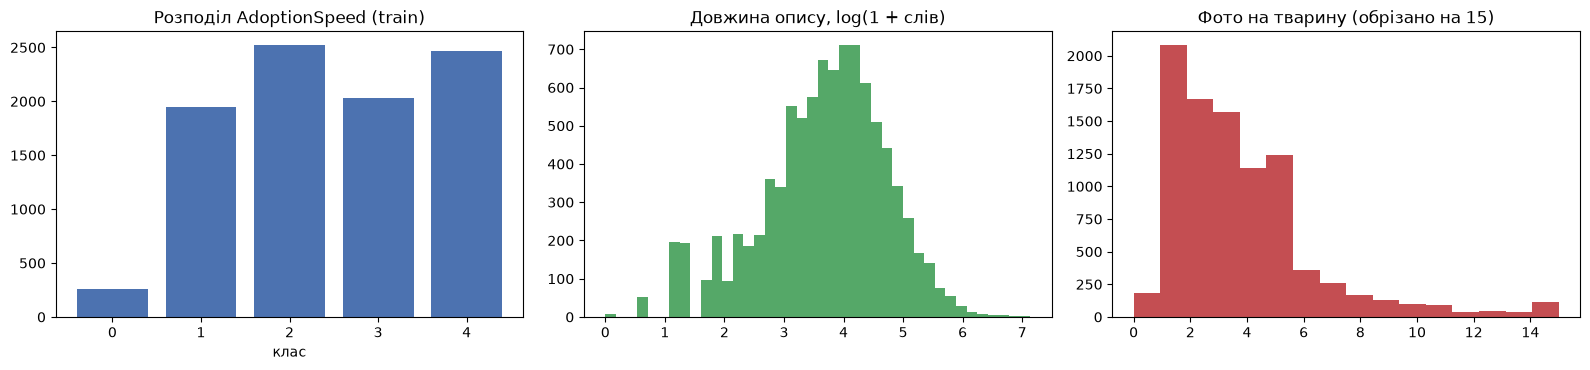

In [6]:
y = train_df[TGT].to_numpy()
dist = train_df[TGT].value_counts().sort_index()
print('Розподіл цілі (train):')
print(pd.DataFrame({'кількість': dist, 'частка': (dist / dist.sum()).round(3)}).T.to_string())

words_train = train_df[TXT].str.split().str.len()
summary = pd.DataFrame({
    'рядків': [len(train_df), len(test_df)],
    'порожній опис, %': [100 * (train_df[TXT].str.strip() == '').mean(), 100 * (test_df[TXT].str.strip() == '').mean()],
    'слів в описі (медіана)': [words_train.median(), test_df[TXT].str.split().str.len().median()],
    'є фото, %': [100 * (photos_train > 0).mean(), 100 * (photos_test > 0).mean()],
    'фото на тварину (медіана)': [photos_train.median(), photos_test.median()],
}, index=['train', 'test']).round(1)
print()
print(summary.to_string())

print('\nСередня ціль за квінтилями довжини опису (у словах):')
print(train_df.groupby(pd.qcut(words_train, 5, duplicates='drop'), observed=True)[TGT].agg(['mean', 'size']).round(2).T.to_string())
photo_col = pick_col(train_df.columns, 'PhotoAmt')
photo_counts = photos_train if image_index else (train_df[photo_col] if photo_col else None)
if photo_counts is not None:
    print('\nСередня ціль за кількістю фото (' + ('знайдені файли' if image_index else photo_col) + '):')
    print(train_df.groupby(photo_counts.clip(upper=10).rename('фото'))[TGT].agg(['mean', 'size']).round(2).T.to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].bar(dist.index.astype(str), dist.values, color='#4C72B0')
axes[0].set_title('Розподіл AdoptionSpeed (train)')
axes[0].set_xlabel('клас')
axes[1].hist(np.log1p(words_train), bins=40, color='#55A868')
axes[1].set_title('Довжина опису, log(1 + слів)')
if photo_counts is not None:
    axes[2].hist(photo_counts.clip(upper=15), bins=16, color='#C44E52')
    axes[2].set_title('Фото на тварину (обрізано на 15)')
else:
    axes[2].axis('off')
plt.tight_layout()
plt.show()

## 3. Ознаки

Train і test обробляю разом (`full`), щоб категорії, словник TF-IDF і PCA були однакові. Ціль на цьому етапі не використовується, тож витоку немає.

### 3.1. Табличні ознаки

Беру всі колонки, які є і в train, і в test (крім ID, цілі й тексту):
- рядкові категорії (порода, колір, стать…) і відомі числові коди (`Breed1`, `State`…) отримують тип `category`, з яким LightGBM працює напряму; для категорій з понад 30 значеннями додаю ще частоту значення;
- `RescuerID` не подаю як категорію (у тесті можуть бути нові волонтери), а рахую, скільки оголошень у цього волонтера. В оригінальному змаганні це була одна з найсильніших ознак;
- для імені тварини (якщо така колонка є) рахую довжину і те, чи ім'я взагалі вказане;
- рядкові колонки, де майже всі значення унікальні, пропускаю (це ідентифікатори або вільний текст);
- кількість знайдених фото теж іде в ознаки.

In [7]:
n_train = len(train_df)
full = pd.concat([train_df.drop(columns=[TGT]), test_df], ignore_index=True)
common_cols = [c for c in train_df.columns if c in test_df.columns and c not in (ID, TGT, TXT)]

tab = pd.DataFrame(index=full.index)
skipped = []
for c in common_cols:
    s = full[c]
    if c == GRP:
        tab['rescuer_count'] = s.map(s.value_counts()).astype(float)
        continue
    if str(c).lower() == 'name':
        name = s.fillna('').astype(str).str.strip()
        tab['name_len'] = name.str.len().astype(float)
        tab['name_missing'] = (name.eq('') | name.str.lower().str.contains('no name|unknown|nameless')).astype(int)
        continue
    is_num = pd.api.types.is_numeric_dtype(s)
    if is_num and c not in CATEGORICAL_HINTS:
        tab[c] = s.astype(float)
        continue
    s = s.astype('string').fillna('NA')
    n_unique = s.nunique()
    if not is_num and n_unique > 0.5 * len(s):
        skipped.append(c)
        continue
    tab[c] = pd.Categorical(s, categories=sorted(s.unique()))
    if n_unique > 30:
        tab[f'{c}_freq'] = s.map(s.value_counts(normalize=True)).astype(float)
if image_index:
    tab['img_n_files'] = full[ID].map(lambda p: len(image_index.get(p, []))).astype(float)

print(f'Табличних ознак: {tab.shape[1]} (з них категоріальних: {sum(str(t) == "category" for t in tab.dtypes)})')
if skipped:
    print('Пропущено (схожі на ID / вільний текст):', skipped)
print(tab.head(3).to_string())

Табличних ознак: 14 (з них категоріальних: 10)
  Type   Age       Breed1  Breed1_freq  Gender Color1 Color2 MaturitySize FurLength Vaccinated Sterilized   Health  Fee  PhotoAmt
0  Cat   3.0      Siamese     0.017509  Female  Brown  Cream       Medium     Short         No         No  Healthy  0.0       6.0
1  Dog   1.0  Mixed Breed     0.401231  Female  Black  Brown       Medium     Short   Not Sure   Not Sure  Healthy  0.0       4.0
2  Dog  12.0  Mixed Breed     0.401231    Male  Black  Brown       Medium    Medium        Yes         No  Healthy  0.0       3.0


### 3.2. Текст: статистики й TF-IDF

Прості статистики опису: довжина в символах і словах, частка унікальних слів, великих літер і не-ASCII символів (частина описів малайською чи китайською), кількість цифр, знаків оклику й речень.

Далі TF-IDF двох видів: слова й біграми (зміст) і символьні n-грами 2-5 (стійкі до помилок, змішаних мов і форм слів). Обидві матриці мають десятки тисяч колонок, тому стискаю кожну TruncatedSVD до 32 компонент. Це приблизно LSA: компоненти ловлять теми описів.

In [8]:
text = full[TXT].fillna('').astype(str)
n_chars = text.str.len()
tokens = text.str.split()
n_words = tokens.str.len()
text_stats = pd.DataFrame({
    'txt_chars': n_chars,
    'txt_words': n_words,
    'txt_unique_ratio': tokens.map(lambda w: len({x.lower() for x in w}) / max(len(w), 1)),
    'txt_avg_word_len': n_chars / n_words.clip(lower=1),
    'txt_upper_ratio': text.str.count(r'[A-Z]') / n_chars.clip(lower=1),
    'txt_nonascii_ratio': text.str.count(r'[^\x00-\x7F]') / n_chars.clip(lower=1),
    'txt_digits': text.str.count(r'\d'),
    'txt_exclaims': text.str.count('!'),
    'txt_sentences': text.str.count(r'[.!?]+'),
    'txt_empty': (n_chars == 0).astype(int),
}).astype(float)


def svd_block(X, k, prefix):
    k = int(min(k, X.shape[1] - 1, X.shape[0] - 1))
    if k < 1:
        return pd.DataFrame(index=full.index)
    Z = TruncatedSVD(n_components=k, random_state=SEED, n_iter=7).fit_transform(X)
    return pd.DataFrame(Z, columns=[f'{prefix}{i}' for i in range(k)], index=full.index)


t0 = time.time()
min_df = 3 if len(text) > 1000 else 1
blocks = []
for name, vec, k in [
    ('tfw_svd', TfidfVectorizer(ngram_range=(1, 2), min_df=min_df, max_features=50000, sublinear_tf=True,
                                strip_accents='unicode'), TFIDF_WORD_SVD),
    ('tfc_svd', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=min_df, max_features=50000,
                                sublinear_tf=True), TFIDF_CHAR_SVD),
]:
    try:
        X_sparse = vec.fit_transform(text)
    except ValueError as e:                                  # напр., усі описи порожні
        print(f'{name}: пропускаю ({e})')
        continue
    blocks.append(svd_block(X_sparse, k, name))
    print(f'{name}: TF-IDF {X_sparse.shape} -> SVD {blocks[-1].shape[1]}')
tfidf_feats = pd.concat(blocks, axis=1) if blocks else None
print(f'Готово за {time.time() - t0:.1f} с')

tfw_svd: TF-IDF (11537, 41880) -> SVD 32


tfc_svd: TF-IDF (11537, 50000) -> SVD 32
Готово за 5.2 с


### 3.3. Текст: ембединги трансформера

TF-IDF рахує слова, але не розуміє змісту. Тому додаю ембединги речень з попередньо навченого трансформера `paraphrase-multilingual-MiniLM-L12-v2` (sentence-transformers, 12 шарів, вектор 384). Модель багатомовна, що корисно для малайських і китайських описів. Я її не донавчаю: подаю опис (до 256 токенів), усереднюю приховані стани по токенах (mean pooling, як у sentence-transformers) і стискаю PCA до 32 компонент.

Ембединги кешую на диск. Перед PCA округлюю їх до 4 знаків, щоб дрібний шум обчислень на GPU не змінював результат між запусками.

In [9]:
def cache_key(*parts):
    h = hashlib.sha1()
    for p in parts:
        h.update(str(p).encode('utf-8'))
        h.update(b'\x00')
    return h.hexdigest()[:16]


def pca_block(E, k, prefix, rows=None):
    """PCA по рядках rows (де є дані); інші рядки -> NaN (LightGBM сам обробляє пропуски)."""
    rows = np.arange(len(E)) if rows is None else np.asarray(rows)
    k = int(min(k, E.shape[1], len(rows) - 1))
    out = np.full((len(E), max(k, 0)), np.nan, dtype=np.float32)
    if k >= 1:
        Er = np.round(E[rows].astype(np.float64), 4)
        out[rows] = PCA(n_components=k, random_state=SEED, svd_solver='full').fit_transform(Er)
    return pd.DataFrame(out, columns=[f'{prefix}{i}' for i in range(out.shape[1])], index=full.index)


def embed_texts(texts, model_name):
    from transformers import AutoModel, AutoTokenizer
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        model = AutoModel.from_pretrained(model_name).to(DEVICE).eval()
    except Exception as e:
        raise RuntimeError(
            f'Не вдалося завантажити текстову модель {model_name!r}: {e}\n'
            'На Kaggle: Settings -> Internet on, або додайте модель як Dataset і вкажіть шлях у TEXT_MODEL, '
            'або поставте USE_TEXT_EMB = False.') from e
    order = np.argsort([len(t) for t in texts], kind='stable')   # схожі за довжиною тексти в одному батчі
    out = None
    with torch.inference_mode():
        for start in range(0, len(texts), TEXT_BATCH_SIZE):
            idx = order[start:start + TEXT_BATCH_SIZE]
            batch = tokenizer([texts[i] for i in idx], padding=True, truncation=True,
                              max_length=TEXT_MAX_LEN, return_tensors='pt').to(DEVICE)
            hidden = model(**batch).last_hidden_state
            mask = batch['attention_mask'].unsqueeze(-1).to(hidden.dtype)
            emb = ((hidden * mask).sum(1) / mask.sum(1).clamp(min=1e-6)).float().cpu().numpy()
            if out is None:
                out = np.zeros((len(texts), emb.shape[1]), dtype=np.float32)
            out[idx] = emb
    return out


text_emb_feats = None
if USE_TEXT_EMB:
    t0 = time.time()
    texts = text.tolist()
    key = cache_key(TEXT_MODEL, TEXT_MAX_LEN, hashlib.sha1('\x00'.join(texts).encode('utf-8')).hexdigest())
    cache_file = CACHE / f'text_emb_{key}.npy'
    if cache_file.exists():
        E_text = np.load(cache_file)
        print('Текстові ембединги - з кешу', cache_file.name)
    else:
        E_text = embed_texts(texts, TEXT_MODEL)
        np.save(cache_file, E_text)
    text_emb_feats = pca_block(E_text, TEXT_PCA_DIM, 'temb_pca')
    print(f'Ембединги {E_text.shape} -> PCA {text_emb_feats.shape[1]} за {time.time() - t0:.1f} с ({DEVICE})')
else:
    print('USE_TEXT_EMB = False - пропускаю')

Ембединги (11537, 384) -> PCA 32 за 17.4 с (mps)


### 3.4. Зображення: ембединги попередньо навченої CNN

Для кожного фото рахую ембединг EfficientNet-B0 з вагами ImageNet: вихід після global average pooling, 1280 чисел. CNN використовую лише як екстрактор ознак, без донавчання. Це один прохід по фото, тож на GPU відносно швидко. Препроцесинг стандартний для ImageNet: зменшую коротшу сторону до 224, вирізаю центр 224×224 і нормалізую.

Для тварини усереднюю ембединги її перших `MAX_IMAGES_PER_PET` фото. Якщо фото немає або файл битий, ембединг лишається NaN, і я додаю ознаку `img_missing`. Потім стискаю PCA до 32 компонент, щоб 1280 ознак з невеликим внеском кожна не заглушили решту. Додаю також середні розміри фото.

За потреби бекбон можна замінити (`IMAGE_BACKBONE`): `densenet121`, `resnet50` або будь-яку CLIP / SigLIP модель з Hugging Face (`'hf:google/siglip2-base-patch16-224'`).

In [10]:
from PIL import Image


def get_image_encoder(backbone, weights_path=None):
    """Повертає (model, transform, feature_fn): feature_fn(batch) -> тензор ознак [B, D]."""
    import torch.nn as nn
    if backbone.startswith('hf:'):
        from transformers import AutoImageProcessor, AutoModel
        from transformers.utils import logging as hf_logging
        hf_logging.set_verbosity_error()
        name = backbone[3:]
        processor = AutoImageProcessor.from_pretrained(name)
        model = AutoModel.from_pretrained(name)

        def transform(img):
            return processor(images=img, return_tensors='pt')['pixel_values'][0]

        def feature_fn(x):
            out = model.get_image_features(pixel_values=x)
            if torch.is_tensor(out):
                return out
            if getattr(out, 'pooler_output', None) is not None:
                return out.pooler_output
            return out.last_hidden_state.mean(1)
        return model, transform, feature_fn

    import torchvision
    from torchvision import transforms as T
    zoo = {'efficientnet_b0': (torchvision.models.efficientnet_b0, 'IMAGENET1K_V1', 'classifier'),
           'densenet121': (torchvision.models.densenet121, 'IMAGENET1K_V1', 'classifier'),
           'resnet50': (torchvision.models.resnet50, 'IMAGENET1K_V2', 'fc')}
    if backbone not in zoo:
        raise ValueError(f'Невідомий IMAGE_BACKBONE {backbone!r}. Варіанти: {list(zoo)} або "hf:<модель>".')
    ctor, weights, head = zoo[backbone]
    if weights_path:
        model = ctor(weights=None)
        model.load_state_dict(torch.load(weights_path, map_location='cpu', weights_only=True))
    else:
        model = ctor(weights=weights)
    setattr(model, head, nn.Identity())                      # прибираю класифікатор -> лишається GAP-вектор
    transform = T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.ToTensor(),
                           T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    return model, transform, model


class PetImages(torch.utils.data.Dataset):
    def __init__(self, paths, transform, blank_shape):
        self.paths, self.transform, self.blank_shape = paths, transform, blank_shape

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        try:
            with Image.open(self.paths[i]) as im:
                im = im.convert('RGB')
                w, h = im.size
                x = self.transform(im)
            return x, torch.tensor([w, h, 1.0])
        except Exception:                                    # битий файл -> нулі й прапорець ok = 0
            return torch.zeros(self.blank_shape), torch.tensor([0.0, 0.0, 0.0])


def embed_images(paths):
    try:
        model, transform, feature_fn = get_image_encoder(IMAGE_BACKBONE, IMAGE_WEIGHTS_PATH)
    except Exception as e:
        raise RuntimeError(
            f'Не вдалося створити {IMAGE_BACKBONE!r}: {e}\nНа Kaggle: Settings -> Internet on, або додайте файл '
            'ваг як Dataset і вкажіть його в IMAGE_WEIGHTS_PATH.') from e
    model = model.to(DEVICE).eval()
    blank_shape = tuple(transform(Image.new('RGB', (IMG_SIZE, IMG_SIZE))).shape)
    loader = torch.utils.data.DataLoader(PetImages(paths, transform, blank_shape), batch_size=IMG_BATCH_SIZE,
                                         shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
    feats, meta = [], []
    with torch.inference_mode():
        for xb, mb in loader:
            feats.append(feature_fn(xb.to(DEVICE)).float().cpu().numpy())
            meta.append(mb.numpy())
    return np.concatenate(feats), np.concatenate(meta)


img_feats = None
if USE_IMAGES and image_index:
    t0 = time.time()
    pet_ids = full[ID].tolist()
    flat_paths, owner = [], []
    for i, pid in enumerate(pet_ids):
        for p in image_index.get(pid, [])[:MAX_IMAGES_PER_PET]:
            flat_paths.append(p)
            owner.append(i)
    owner = np.asarray(owner, dtype=int)
    key = cache_key(IMAGE_BACKBONE, IMAGE_WEIGHTS_PATH, IMG_SIZE, '\x00'.join(flat_paths))
    cache_file = CACHE / f'img_emb_{key}.npz'
    if cache_file.exists():
        cached = np.load(cache_file)
        F_img, M_img = cached['feats'], cached['meta']
        print('Ембединги фото - з кешу', cache_file.name)
    else:
        print(f'Рахую ембединги для {len(flat_paths)} фото ({IMAGE_BACKBONE}, {DEVICE}, num_workers={NUM_WORKERS})...')
        F_img, M_img = embed_images(flat_paths)
        np.savez(cache_file, feats=F_img, meta=M_img)
    ok = M_img[:, 2] > 0
    n_pets = len(pet_ids)
    sums = np.zeros((n_pets, F_img.shape[1]), dtype=np.float64)
    wh = np.zeros((n_pets, 2), dtype=np.float64)
    counts = np.zeros(n_pets, dtype=np.float64)
    np.add.at(sums, owner[ok], F_img[ok])
    np.add.at(wh, owner[ok], M_img[ok, :2])
    np.add.at(counts, owner[ok], 1.0)
    has_img = counts > 0
    mean_emb = np.full_like(sums, np.nan)
    mean_emb[has_img] = sums[has_img] / counts[has_img, None]
    mean_wh = np.full_like(wh, np.nan)
    mean_wh[has_img] = wh[has_img] / counts[has_img, None]
    img_feats = pd.concat([
        pca_block(mean_emb, IMG_PCA_DIM, 'img_pca', rows=np.where(has_img)[0]),
        pd.DataFrame({'img_n_used': counts, 'img_missing': (~has_img).astype(int), 'img_w': mean_wh[:, 0],
                      'img_h': mean_wh[:, 1], 'img_aspect': mean_wh[:, 0] / mean_wh[:, 1]}, index=full.index),
    ], axis=1)
    print(f'Фото: {len(flat_paths)} файлів, битих {int((~ok).sum())}; тварин з ембедингом {has_img.mean():.1%}; '
          f'ембединг {F_img.shape[1]} -> PCA {IMG_PCA_DIM}; {time.time() - t0:.1f} с')
elif USE_IMAGES:
    print('Фото не знайдено - гілку зображень пропущено (у проксі-режимі це очікувано).')
else:
    print('USE_IMAGES = False - пропускаю')

Фото не знайдено - гілку зображень пропущено (у проксі-режимі це очікувано).


### 3.5. Збираю матрицю ознак

Склеюю всі групи, чищу назви колонок (LightGBM не приймає деякі символи) і зберігаю матрицю в `features.pkl` разом з переліком груп: з цього файлу можна повторити навчання без перерахунку ембедингів.

In [11]:
json_feats = None
if json_by_id is not None:
    json_feats = json_by_id.reindex(full[ID].to_numpy()).set_axis(full.index)

groups = {'tabular': tab, 'text_stats': text_stats, 'tfidf_svd': tfidf_feats, 'text_emb': text_emb_feats,
          'image': img_feats, 'json_meta': json_feats}
groups = {g: df for g, df in groups.items() if df is not None and df.shape[1] > 0}

names, FEATURE_GROUPS, seen = [], {}, set()
for g, df in groups.items():
    FEATURE_GROUPS[g] = []
    for c in df.columns:
        n = re.sub(r'[^0-9A-Za-z_]+', '_', str(c)).strip('_') or 'f'
        while n in seen:
            n += '_'
        seen.add(n)
        names.append(n)
        FEATURE_GROUPS[g].append(n)
X_all = pd.concat(list(groups.values()), axis=1)
X_all.columns = names

if not USE_LGB:                                               # HistGradientBoosting: категорій не більше 255
    for c in X_all.columns:
        if isinstance(X_all[c].dtype, pd.CategoricalDtype) and len(X_all[c].cat.categories) > 250:
            X_all[c] = X_all[c].cat.codes.astype(float)

X_train = X_all.iloc[:n_train].reset_index(drop=True)
X_test = X_all.iloc[n_train:].reset_index(drop=True)
X_all.to_pickle(OUT / 'features.pkl')
(OUT / 'feature_groups.json').write_text(json.dumps(FEATURE_GROUPS, indent=1))

print(pd.Series({g: len(c) for g, c in FEATURE_GROUPS.items()}, name='ознак').to_frame().T.to_string())
print(f'Разом: {X_train.shape[1]} ознак; train {X_train.shape}, test {X_test.shape}')

       tabular  text_stats  tfidf_svd  text_emb
ознак       14          10         64        32
Разом: 120 ознак; train (9229, 120), test (2308, 120)


## 4. Модель і валідація

Задачу розв'язую як регресію, бо ціль порядкова: помилка «0 замість 4» гірша за «3 замість 4», і QWK рахує саме так. Класифікатор цього порядку не знає, а регресія знає. Отже, я навчаю LightGBM з RMSE-втратою, а класи отримую порогами.

Пороги за замовчуванням (середини між класами: 0.5, 1.5, …) для QWK не оптимальні: регресія стягує прогнози до середнього, і крайні класи майже не з'являються. Тому пороги я підбираю на out-of-fold (OOF) прогнозах: по черзі зсуваю кожен поріг по сітці між сусідніми й лишаю положення з найвищим QWK, і так кілька проходів. Це варіант OptimizedRounder, відомого з PetFinder-2019, але без випадкового старту, тож результат детермінований.

Валідація: 5-fold StratifiedKFold за класами цілі. Якщо в даних є `RescuerID`, беру StratifiedGroupKFold, щоб оголошення одного волонтера не потрапляли водночас у train і валідацію (в оригінальному змаганні тестові волонтери не перетиналися з train). Кожен фолд навчаю з трьома seed-ами й усереднюю. Кількість дерев визначає early stopping на валідаційному фолді, через це OOF-оцінка трохи оптимістична, і остаточно я орієнтуюся на лідерборд.

Щоб не обманювати себе, рахую три QWK:
1. з порогами за замовчуванням;
2. з порогами, підібраними на всіх OOF (трохи завищено: пороги бачили ці самі дані);
3. вкладений варіант без витоку: пороги для кожного фолду підбираю лише на інших фолдах.

Для порівняння є наївні бейзлайни: завжди найчастіший клас і завжди округлене середнє. Будь-який сталий прогноз дає QWK = 0.

In [12]:
def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))


def qwk(y_true, y_pred):
    """Quadratic weighted kappa (швидка версія; збігається з cohen_kappa_score(weights='quadratic'))."""
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    lo = min(y_true.min(), y_pred.min())
    n = max(y_true.max(), y_pred.max()) - lo + 1
    O = np.bincount((y_true - lo) * n + (y_pred - lo), minlength=n * n).reshape(n, n).astype(float)
    W = np.subtract.outer(np.arange(n), np.arange(n)) ** 2.0
    E = np.outer(O.sum(1), O.sum(0)) / O.sum()
    denom = (W * E).sum()
    return float(1.0 - (W * O).sum() / denom) if denom > 0 else 0.0


def apply_thresholds(pred, thresholds, classes=None):
    classes = CLASSES if classes is None else np.asarray(classes)
    return classes[np.searchsorted(np.asarray(thresholds), pred, side='right')]


class OptimizedRounder:
    """Пороги «регресія -> клас», що максимізують QWK: покоординатний пошук по сітці, детермінований."""

    def __init__(self, classes, n_passes=3, n_grid=41):
        self.classes = np.asarray(classes)
        self.n_passes, self.n_grid = n_passes, n_grid

    def fit(self, pred, y_true):
        c = self.classes.astype(float)
        thr = (c[:-1] + c[1:]) / 2
        best = qwk(y_true, apply_thresholds(pred, thr, self.classes))
        for _ in range(self.n_passes):
            for i in range(len(thr)):
                lo = thr[i - 1] if i > 0 else c[0] - 0.5
                hi = thr[i + 1] if i < len(thr) - 1 else c[-1] + 0.5
                for cand in np.linspace(lo, hi, self.n_grid)[1:-1]:
                    trial = thr.copy()
                    trial[i] = cand
                    score = qwk(y_true, apply_thresholds(pred, trial, self.classes))
                    if score > best + 1e-9:
                        best, thr = score, trial
        self.thresholds_, self.score_ = thr, best
        return self


def distribution_thresholds(pred, y_ref, classes=None):
    """Пороги, за яких частки класів у прогнозі такі самі, як у y_ref."""
    classes = CLASSES if classes is None else classes
    shares = np.array([(y_ref == c).mean() for c in classes])
    return np.quantile(pred, np.cumsum(shares)[:-1])


def nested_qwk(oof, y_true, folds):
    """Вкладений QWK: пороги для кожного фолду підібрано лише на інших фолдах."""
    pred = np.empty_like(y_true)
    for tr, va in folds:
        thr = OptimizedRounder(CLASSES).fit(oof[tr], y_true[tr]).thresholds_
        pred[va] = apply_thresholds(oof[va], thr)
    return qwk(y_true, pred)


def make_model(params, seed, n_estimators=None):
    p = dict(params)
    if USE_LGB:
        if n_estimators is not None:
            p['n_estimators'] = int(n_estimators)
        return lgb.LGBMRegressor(**p, random_state=seed)
    from sklearn.ensemble import HistGradientBoostingRegressor
    if n_estimators is not None:
        p.update(max_iter=int(n_estimators), early_stopping=False)
    return HistGradientBoostingRegressor(**p, categorical_features='from_dtype', random_state=seed)


def fit_model(params, seed, X_tr, y_tr, X_va=None, y_va=None, n_estimators=None):
    """Навчає модель; повертає (model, кількість використаних дерев / ітерацій)."""
    model = make_model(params, seed, n_estimators)
    if USE_LGB and X_va is not None:
        eval_data = dict(eval_X=(X_va,), eval_y=(y_va,)) if LGB_EVAL_XY else dict(eval_set=[(X_va, y_va)])
        model.fit(X_tr, y_tr, **eval_data, eval_metric='rmse',
                  callbacks=[lgb.early_stopping(EARLY_STOPPING, verbose=False)])
        return model, int(model.best_iteration_ or model.n_estimators)
    model.fit(X_tr, y_tr)
    return model, int(model.n_estimators if USE_LGB else model.n_iter_)


def run_cv(X, y_true, folds, params, seeds, X_test=None, verbose=True):
    oof = np.zeros(len(y_true))
    test_pred = None if X_test is None else np.zeros(len(X_test))
    iters, rows = [], []
    for k, (tr, va) in enumerate(folds):
        p_va = np.zeros(len(va))
        for s in seeds:
            model, n_used = fit_model(params, s, X.iloc[tr], y_true[tr], X.iloc[va], y_true[va])
            p_va += model.predict(X.iloc[va]) / len(seeds)
            if X_test is not None:
                test_pred += model.predict(X_test) / (len(seeds) * len(folds))
            iters.append(n_used)
        oof[va] = p_va
        rows.append({'fold': k, 'n_valid': len(va), 'rmse': rmse(y_true[va], p_va), 'trees': int(np.mean(iters[-len(seeds):]))})
        if verbose:
            print(f'  fold {k}: n={len(va)}, rmse={rows[-1]["rmse"]:.4f}, дерев={rows[-1]["trees"]}')
    return {'oof': oof, 'test': test_pred, 'iters': iters, 'folds': pd.DataFrame(rows)}


groups_for_cv = train_df[GRP].astype(str).to_numpy() if GRP else None
if groups_for_cv is not None:
    folds = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_train, y, groups_for_cv))
else:
    folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_train, y))
print('Схема CV:', 'StratifiedGroupKFold за ' + GRP if GRP else 'StratifiedKFold', f'({N_FOLDS} фолдів)')

if USE_LGB:
    PARAMS = dict(LGB_PARAMS, n_jobs=N_THREADS, deterministic=True, force_row_wise=True, verbose=-1)
else:
    PARAMS = dict(HGB_PARAMS)
if TUNED_PARAMS:
    PARAMS.update(TUNED_PARAMS)
    print('Використовую TUNED_PARAMS:', TUNED_PARAMS)

Схема CV: StratifiedKFold (5 фолдів)


### 4.1. (Опційно) Optuna

За замовчуванням вимкнено (`USE_OPTUNA = False`). Якщо ввімкнути, Optuna (TPE-семплер з фіксованим seed) підбирає кілька параметрів LightGBM за OOF RMSE на тих самих фолдах, з одним seed і вищим learning rate, щоб було швидше. Після підбору я копіюю найкращі параметри в `TUNED_PARAMS` і вимикаю `USE_OPTUNA`: тоді фінальний запуск не залежить від кількості спроб і точно відтворює сабміт. Optuna не є AutoML: модель і ознаки вона не обирає, лише перебирає значення в діапазонах, які я задав.

In [13]:
if USE_OPTUNA and not USE_LGB:
    print('Optuna налаштована лише для LightGBM - пропускаю.')
elif USE_OPTUNA:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    def objective(trial):
        p = dict(PARAMS, learning_rate=0.05,
                 num_leaves=trial.suggest_int('num_leaves', 8, 128, log=True),
                 min_child_samples=trial.suggest_int('min_child_samples', 5, 150, log=True),
                 colsample_bytree=trial.suggest_float('colsample_bytree', 0.2, 0.9),
                 subsample=trial.suggest_float('subsample', 0.5, 1.0),
                 reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 30.0, log=True),
                 reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True))
        return rmse(y, run_cv(X_train, y, folds, p, [SEED], verbose=False)['oof'])

    t0 = time.time()
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=OPTUNA_TRIALS)
    best_params = {k: (round(v, 6) if isinstance(v, float) else v) for k, v in study.best_params.items()}
    PARAMS.update(best_params)
    (OUT / 'optuna_best_params.json').write_text(json.dumps(best_params, indent=2))
    print(f'{len(study.trials)} спроб за {time.time() - t0:.0f} с; найкращий OOF RMSE = {study.best_value:.4f}')
    print('Для відтворюваного фінального запуску вставте в CONFIG:\nTUNED_PARAMS =', best_params)
else:
    print('USE_OPTUNA = False - беру параметри з CONFIG:', {k: PARAMS[k] for k in list(PARAMS)[:8]}, '...')

USE_OPTUNA = False - беру параметри з CONFIG: {'objective': 'regression', 'learning_rate': 0.02, 'n_estimators': 5000, 'num_leaves': 31, 'min_child_samples': 30, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.5} ...


### 4.2. Крос-валідація основної моделі

In [14]:
t0 = time.time()
cv = run_cv(X_train, y, folds, PARAMS, MODEL_SEEDS, X_test=X_test)
oof = cv['oof']
print(f'CV за {time.time() - t0:.0f} с')

default_thr = (CLASSES[:-1] + CLASSES[1:]) / 2
rounder = OptimizedRounder(CLASSES).fit(oof, y)
THRESHOLDS = rounder.thresholds_
oof_cls = apply_thresholds(oof, THRESHOLDS)
assert abs(qwk(y, oof_cls) - cohen_kappa_score(y, oof_cls, weights='quadratic')) < 1e-9   # перевірка своєї qwk()

fold_table = cv['folds'].copy()
fold_table['qwk_default_thr'] = [qwk(y[va], apply_thresholds(oof[va], default_thr)) for _, va in folds]
fold_table['qwk_opt_thr'] = [qwk(y[va], oof_cls[va]) for _, va in folds]

majority = CLASSES[np.argmax([(y == c).sum() for c in CLASSES])]
mean_class = int(np.clip(np.round(y.mean()), CLASSES.min(), CLASSES.max()))
CV_METRICS = {
    'oof_rmse': rmse(y, oof),
    'qwk_default_thresholds': qwk(y, apply_thresholds(oof, default_thr)),
    'qwk_optimized_thresholds': qwk(y, oof_cls),
    'qwk_nested_thresholds': nested_qwk(oof, y, folds),
}
BASELINES = {
    'rmse_predict_mean': rmse(y, np.full(len(y), y.mean())),
    f'qwk_always_{majority}_(most_frequent)': qwk(y, np.full(len(y), majority)),
    f'qwk_always_{mean_class}_(rounded_mean)': qwk(y, np.full(len(y), mean_class)),
}

print('\nПо фолдах (пороги - глобальні з OOF):')
print(fold_table.round(4).to_string(index=False))
print('\nOOF-метрики:')
for k, v in CV_METRICS.items():
    print(f'  {k:<28} {v:.4f}')
print('Наївні бейзлайни:')
for k, v in BASELINES.items():
    print(f'  {k:<28} {v:.4f}')
print('\nПороги (типові):     ', np.round(default_thr, 3).tolist())
print('Пороги (підібрані):  ', np.round(THRESHOLDS, 3).tolist())
print('\nМатриця помилок OOF (рядки - правда, стовпці - прогноз):')
print(pd.crosstab(pd.Series(y, name='true'), pd.Series(oof_cls, name='pred')).to_string())

  fold 0: n=1846, rmse=1.0429, дерев=503


  fold 1: n=1846, rmse=1.0337, дерев=1967


  fold 2: n=1846, rmse=1.0392, дерев=925


  fold 3: n=1846, rmse=1.0425, дерев=1419


  fold 4: n=1845, rmse=1.0228, дерев=1040
CV за 74 с



По фолдах (пороги - глобальні з OOF):
 fold  n_valid   rmse  trees  qwk_default_thr  qwk_opt_thr
    0     1846 1.0429    503           0.3223       0.4357
    1     1846 1.0337   1967           0.3744       0.4474
    2     1846 1.0392    925           0.3315       0.4319
    3     1846 1.0425   1419           0.3557       0.4446
    4     1845 1.0228   1040           0.3455       0.4677

OOF-метрики:
  oof_rmse                     1.0363
  qwk_default_thresholds       0.3462
  qwk_optimized_thresholds     0.4456
  qwk_nested_thresholds        0.4381
Наївні бейзлайни:
  rmse_predict_mean            1.1732
  qwk_always_2_(most_frequent) 0.0000
  qwk_always_2_(rounded_mean)  0.0000

Пороги (типові):      [0.5, 1.5, 2.5, 3.5]
Пороги (підібрані):   [1.606, 2.05, 2.493, 2.995]

Матриця помилок OOF (рядки - правда, стовпці - прогноз):
pred    0    1    2    3     4
true                          
0      39   60  106   39    19
1     171  626  719  349    81
2      61  578  990  631   262
3 

### 4.3. Абляція: що дає кожна група ознак

Ту саму схему CV проганяю на підмножинах ознак. Щоб було швидше, беру один seed і вищий learning rate, тому абсолютні числа трохи нижчі, ніж в основної моделі. Дивитися треба на різницю між рядками.

In [15]:
ABLATION = []
if RUN_ABLATION:
    t0 = time.time()
    fast = dict(PARAMS, learning_rate=0.05) if USE_LGB else dict(PARAMS, learning_rate=0.08)
    G = FEATURE_GROUPS
    base = [g for g in ('tabular', 'json_meta') if g in G]
    txt_simple = [g for g in ('text_stats', 'tfidf_svd') if g in G]
    txt_all = txt_simple + [g for g in ('text_emb',) if g in G]
    variants = [('табличні', base), ('табличні + текст (статистики, TF-IDF)', base + txt_simple),
                ('табличні + текст (+ ембединги трансформера)', base + txt_all)]
    if 'image' in G:
        variants += [('табличні + текст + фото (усе)', base + txt_all + ['image']),
                     ('лише текст + фото (без табличних)', txt_all + ['image']),
                     ('лише фото', ['image'])]
    seen_sets = set()
    for label, gs in variants:
        cols = [c for g in gs for c in G[g]]
        if not cols or tuple(cols) in seen_sets:
            continue
        seen_sets.add(tuple(cols))
        res = run_cv(X_train[cols], y, folds, fast, [SEED], verbose=False)
        thr = OptimizedRounder(CLASSES).fit(res['oof'], y).thresholds_
        ABLATION.append({'ознаки': label, 'к-сть': len(cols), 'rmse': rmse(y, res['oof']),
                         'qwk_opt_thr': qwk(y, apply_thresholds(res['oof'], thr)),
                         'qwk_nested': nested_qwk(res['oof'], y, folds)})
    print(pd.DataFrame(ABLATION).round(4).to_string(index=False))
    print(f'\n{time.time() - t0:.0f} с')
else:
    print('RUN_ABLATION = False')

                                     ознаки  к-сть   rmse  qwk_opt_thr  qwk_nested
                                   табличні     14 1.0669       0.4021      0.3992
      табличні + текст (статистики, TF-IDF)     88 1.0405       0.4381      0.4325
табличні + текст (+ ембединги трансформера)    120 1.0441       0.4338      0.4261

25 с


## 5. Фінальне навчання й сабміт

LMS радить перед фінальним прогнозом перенавчити модель на всіх даних, тож:
1. навчаю модель на всьому train з тими самими параметрами; кількість дерев = середня з фолдів × 1.15 (даних на 25 % більше), по одній моделі на кожен seed;
2. за замовчуванням (`FINAL_PREDICTION = 'blend'`) усереднюю її прогноз з прогнозом моделей фолдів (кожна бачила 80 % даних), так результат трохи стабільніший;
3. застосовую пороги, підібрані на OOF, обрізаю результат до діапазону класів і записую CSV з заголовком `PetID,AdoptionSpeed`;
4. поруч зберігаю все, що потрібно для відтворення: пороги, OOF-прогнози, сирі прогнози для тесту, ознаки, параметри й версії бібліотек, а також SHA-256 файлу сабміту. Якщо вписати цей хеш у `EXPECTED_SUBMISSION_SHA256`, ноутбук сам перевірить, що створив той самий файл.

In [16]:
t0 = time.time()
n_full = max(1, int(round(np.mean(cv['iters']) * FULL_FIT_ITER_MULT)))
pred_full = np.zeros(len(X_test))
for s in MODEL_SEEDS:
    model, _ = fit_model(PARAMS, s, X_train, y, n_estimators=n_full)
    pred_full += model.predict(X_test) / len(MODEL_SEEDS)
pred_folds = cv['test']
RAW = {'full': pred_full, 'folds': pred_folds, 'blend': 0.5 * (pred_full + pred_folds)}
raw_test = RAW[FINAL_PREDICTION]

if ROUNDING == 'distribution':
    final_thr = distribution_thresholds(raw_test, y)
else:
    final_thr = THRESHOLDS
labels = np.clip(apply_thresholds(raw_test, final_thr), CLASSES.min(), CLASSES.max()).astype(int)

sub = pd.DataFrame({SUB_COLUMNS[0]: test_df[ID].to_numpy(), SUB_COLUMNS[1]: labels})
if sample_df is not None:                                     # порядок рядків як у sample_submission
    missing = set(sample_df[sample_id_col]) - set(sub[SUB_COLUMNS[0]])
    if missing:
        raise ValueError(f'{len(missing)} PetID із sample_submission немає в прогнозі: {list(missing)[:5]}')
    sub = sub.set_index(SUB_COLUMNS[0]).loc[sample_df[sample_id_col]].reset_index()
sub_path = OUT / ('submission.csv' if MODE == 'competition' else 'submission_proxy.csv')
sub.to_csv(sub_path, index=False)

with open(sub_path, encoding='utf-8') as fh:
    header = fh.readline().strip()
assert header == ','.join(SUB_COLUMNS), header
assert sub[SUB_COLUMNS[0]].is_unique and len(sub) == len(test_df)
SUB_SHA256 = hashlib.sha256(sub_path.read_bytes()).hexdigest()

pd.DataFrame({ID: train_df[ID], 'y': y, 'oof': oof}).to_csv(OUT / 'oof_predictions.csv', index=False)
pd.DataFrame({ID: test_df[ID], **{f'raw_{k}': v for k, v in RAW.items()}}).to_csv(OUT / 'test_raw_predictions.csv', index=False)
run_info = {
    'mode': MODE, 'seed': SEED, 'model_seeds': MODEL_SEEDS, 'n_folds': N_FOLDS,
    'cv_scheme': f'StratifiedGroupKFold({GRP})' if GRP else 'StratifiedKFold',
    'model': 'lightgbm' if USE_LGB else 'sklearn_hgb', 'params': PARAMS, 'full_fit_trees': n_full,
    'final_prediction': FINAL_PREDICTION, 'rounding': ROUNDING, 'classes': CLASSES.tolist(),
    'thresholds_oof': THRESHOLDS.tolist(), 'thresholds_used': np.asarray(final_thr).tolist(),
    'feature_groups': {g: len(c) for g, c in FEATURE_GROUPS.items()},
    'image_backbone': IMAGE_BACKBONE if 'image' in FEATURE_GROUPS else None, 'max_images_per_pet': MAX_IMAGES_PER_PET,
    'text_model': TEXT_MODEL if 'text_emb' in FEATURE_GROUPS else None,
    'submission_file': sub_path.name, 'submission_sha256': SUB_SHA256,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                 'sklearn': sklearn.__version__, 'torch': torch.__version__,
                 'lightgbm': lgb.__version__ if USE_LGB else None},
}
(OUT / 'run_info.json').write_text(json.dumps(run_info, indent=1, default=str))

print(f'Фінальні моделі: {len(MODEL_SEEDS)} x {n_full} дерев, {time.time() - t0:.0f} с')
print(f'Прогноз: {FINAL_PREDICTION}, округлення: {ROUNDING}, пороги: {np.round(final_thr, 3).tolist()}')
print('\nРозподіл класів: прогноз для тесту vs train')
print(pd.DataFrame({'test_pred': pd.Series(labels).value_counts(normalize=True).reindex(CLASSES, fill_value=0),
                    'train': pd.Series(y).value_counts(normalize=True).reindex(CLASSES, fill_value=0)}).round(3).T.to_string())
print(f'\nЗаписано {sub_path} ({len(sub)} рядків), заголовок: {header}')
print('SHA-256:', SUB_SHA256)
if EXPECTED_SUBMISSION_SHA256:
    same = SUB_SHA256 == EXPECTED_SUBMISSION_SHA256
    print('Збігається з поданим файлом:', 'ТАК' if same else 'НІ - ноутбук створив інший файл!')
print(sub.head())

Фінальні моделі: 3 x 1347 дерев, 14 с
Прогноз: blend, округлення: optimized, пороги: [1.606, 2.05, 2.493, 2.995]

Розподіл класів: прогноз для тесту vs train
               0      1      2      3      4
test_pred  0.036  0.172  0.325  0.277  0.190
train      0.028  0.211  0.273  0.220  0.267

Записано outputs/submission_proxy.csv (2308 рядків), заголовок: PetID,AdoptionSpeed
SHA-256: 587fe3f5eb71683e3f268b8dd25df0ee5cffe531071eb497f60a736a57c50afa
        PetID  AdoptionSpeed
0  proxy09074              2
1  proxy06040              1
2  proxy07731              2
3  proxy03649              2
4  proxy00016              3


### 5.1. Підсумок запуску

Ця клітинка збирає всі числа поточного запуску в `run_summary.json`. У проксі-режимі вона ще рахує QWK на відкладеному псевдо-тесті: так я перевіряю, що пороги й перенавчання на всьому train працюють і на даних, яких модель не бачила. У режимі змагання міток тесту немає, тож справжню оцінку дає лише лідерборд Kaggle.

In [17]:
HOLDOUT = []
if MODE == 'proxy':
    truth = proxy_truth.set_index(ID).loc[test_df[ID], TARGET_COL].to_numpy()
    for kind, raw in RAW.items():
        for rounding, thr in [('optimized', THRESHOLDS), ('distribution', distribution_thresholds(raw, y)),
                              ('default', default_thr)]:
            HOLDOUT.append({'prediction': kind, 'rounding': rounding, 'qwk_holdout': qwk(truth, apply_thresholds(raw, thr)),
                            'rmse_holdout': rmse(truth, raw)})
    holdout_table = pd.DataFrame(HOLDOUT).pivot(index='prediction', columns='rounding', values='qwk_holdout')
    print('ПРОКСІ: QWK на відкладених 20 % (модель їх не бачила):')
    print(holdout_table.round(4).to_string())
    print(f'Обраний варіант ({FINAL_PREDICTION}, {ROUNDING}): '
          f'{qwk(truth, apply_thresholds(raw_test, final_thr)):.4f}')

RUN_SUMMARY = {
    'mode': MODE, 'n_train': int(n_train), 'n_test': int(len(test_df)), 'classes': CLASSES.tolist(),
    'class_share_train': {int(c): round(float((y == c).mean()), 4) for c in CLASSES},
    'feature_groups': {g: len(c) for g, c in FEATURE_GROUPS.items()}, 'n_features': int(X_train.shape[1]),
    'cv_scheme': run_info['cv_scheme'], 'model': run_info['model'], 'model_seeds': MODEL_SEEDS,
    'cv_metrics': CV_METRICS, 'baselines': BASELINES, 'fold_table': fold_table.round(5).to_dict(orient='records'),
    'thresholds_default': default_thr.tolist(), 'thresholds_oof': THRESHOLDS.tolist(),
    'ablation': ABLATION, 'holdout': HOLDOUT,
    'final': {'prediction': FINAL_PREDICTION, 'rounding': ROUNDING, 'full_fit_trees': n_full,
              'submission_file': sub_path.name, 'sha256': SUB_SHA256,
              'pred_class_share': {int(c): round(float((labels == c).mean()), 4) for c in CLASSES}},
    'text_model': run_info['text_model'], 'image_backbone': run_info['image_backbone'],
    'device': str(DEVICE), 'runtime_sec': round(time.time() - T_START, 1),
}
(OUT / 'run_summary.json').write_text(json.dumps(RUN_SUMMARY, indent=1, default=str))
print(f'\nЗагальний час виконання: {RUN_SUMMARY["runtime_sec"] / 60:.1f} хв. Файли в {OUT}:')
print(sorted(p.name for p in OUT.iterdir()))

ПРОКСІ: QWK на відкладених 20 % (модель їх не бачила):
rounding    default  distribution  optimized
prediction                                  
blend        0.3234        0.4139     0.4237
folds        0.3174        0.4195     0.4253
full         0.3331        0.4230     0.4276
Обраний варіант (blend, optimized): 0.4237

Загальний час виконання: 2.3 хв. Файли в outputs:
['cache', 'feature_groups.json', 'features.pkl', 'oof_predictions.csv', 'run_info.json', 'run_summary.json', 'submission_proxy.csv', 'test_raw_predictions.csv']


## 6. Результати

> Увага: це результати на ПРОКСІ-даних, а не на даних змагання. Проксі-дані взято з таблиці PetFinder з курсу ML: 11537 тварин, без фото й без `PetID`; 2308 рядків відкладено як псевдо-тест. Гілка зображень тут не працювала (фото немає), її перевірено окремо на синтетичних фото. На даних змагання всі числа будуть інші. Після запуску на Kaggle цю таблицю треба замінити числами з виводу клітинок 4.2-5.1.

Дані: train 9229, тест 2308, класи [0, 1, 2, 3, 4]. Ознак: 120 (tabular: 14, text_stats: 10, tfidf_svd: 64, text_emb: 32). Валідація: StratifiedKFold, модель: lightgbm, seed-и [42, 7, 2026]. Час повного запуску: 2.3 хв (mps).

Основна модель, OOF (крос-валідація на train):

| Метрика | Значення |
|---|---|
| RMSE регресії | 1.0363 (прогноз середнім: 1.1732) |
| QWK, типові пороги | 0.3462 |
| QWK, пороги підібрані на всіх OOF (оптимістично) | 0.4456 |
| QWK, вкладений підбір порогів (без витоку) | 0.4381 |
| Наївний бейзлайн: завжди клас 2 (найчастіший) | 0.0000 |
| Наївний бейзлайн: завжди клас 2 (округлене середнє) | 0.0000 |

По фолдах (глобальні пороги з OOF): 0: 0.436, 1: 0.447, 2: 0.432, 3: 0.445, 4: 0.468.

Пороги: типові [0.5, 1.5, 2.5, 3.5] → підібрані [1.606, 2.05, 2.493, 2.995].

Абляція (1 seed, learning rate 0.05; дивитися треба на різницю між рядками):

| Ознаки | К-сть | RMSE | QWK (пороги на OOF) | QWK (вкладений) |
|---|---|---|---|---|
| табличні | 14 | 1.0669 | 0.4021 | 0.3992 |
| табличні + текст (статистики, TF-IDF) | 88 | 1.0405 | 0.4381 | 0.4325 |
| табличні + текст (+ ембединги трансформера) | 120 | 1.0441 | 0.4338 | 0.4261 |

Порівняно з лише табличними ознаками статистики й TF-IDF опису змінили вкладений QWK на +0.033; ембединги трансформера ще на -0.006.

Ембединги MiniLM тут якості не додали (різниця в межах шуму одного seed). На даних змагання цю таблицю треба перевірити ще раз. Якщо картина та сама, можна поставити `USE_TEXT_EMB = False` або спробувати іншу текстову модель.

Псевдо-тест (відкладені 20 % проксі-даних, модель їх не бачила):

| Прогноз | пороги з OOF | під розподіл train | типові |
|---|---|---|---|
| full | 0.4276 | 0.4230 | 0.3331 |
| folds | 0.4253 | 0.4195 | 0.3174 |
| blend | 0.4237 | 0.4139 | 0.3234 |

Фінальний сабміт: `submission_proxy.csv`, прогноз `blend`, округлення `optimized`, 1347 дерев на модель. Частки класів у прогнозі: {'0': 0.036, '1': 0.172, '2': 0.325, '3': 0.2769, '4': 0.1902} (у train: {'0': 0.0285, '1': 0.2109, '2': 0.2733, '3': 0.2204, '4': 0.267}). SHA-256: `587fe3f5eb71683e3f268b8dd25df0ee5cffe531071eb497f60a736a57c50afa`.

Висновки:

- Підібрані пороги змінили OOF QWK з 0.346 (типові пороги) до 0.438 (вкладена оцінка). Регресія стискає прогнози до середнього, а пороги повертають крайні класи.
- «Оптимістичний» QWK (0.446) вищий за вкладений на 0.008: настільки підбір порогів підганяється під OOF. Як підсумкову оцінку я беру вкладене число.
- На псевдо-тесті обраний варіант дав QWK 0.424, це близько до вкладеної OOF-оцінки 0.438.
- На проксі-даних немає фото й `RescuerID`, тож ці числа не кажуть, чого чекати на даних змагання. Вони лише показують, що весь конвеєр працює від початку до кінця.

Що ще можна покращити: більше фото на тварину, CLIP / SigLIP 2 ембединги замість EfficientNet, кілька моделей в ансамблі (LightGBM + CatBoost + невелика MLP на ембедингах), окремі пороги для кожного seed чи фолду, порядкова голова (CORAL) при донавчанні мультимодального енкодера.

## 7. Як відтворити сабміт

1. Відкрити ноутбук на Kaggle в межах змагання (`Add Input` → дані змагання), `Accelerator: GPU`, `Internet: On` (або підключити ваги як Dataset, див. `IMAGE_WEIGHTS_PATH` / `TEXT_MODEL`).
2. Не змінювати `SEED`, `MODEL_SEEDS`, `N_FOLDS`, `N_THREADS` і параметри. Якщо використовувалась Optuna, вписати знайдені параметри в `TUNED_PARAMS` і поставити `USE_OPTUNA = False`.
3. `Run All`. Ноутбук створює `/kaggle/working/submission.csv` і друкує його SHA-256; той самий хеш лежить у `run_info.json`. Якщо вписати хеш поданого файлу в `EXPECTED_SUBMISSION_SHA256`, ноутбук сам скаже, чи файл збігся.
4. Проміжні результати (ембединги в `cache/`, `features.pkl`, `oof_predictions.csv`, `test_raw_predictions.csv`, `run_info.json`) лежать у тій самій папці. Якщо зберегти версію ноутбука з виводами (`Save Version` → `Save & Run All`), усе це лишиться у вкладці Output.

Що використано: pandas, numpy, scikit-learn (TF-IDF, TruncatedSVD, PCA, KFold), PyTorch + torchvision (EfficientNet-B0, ImageNet), transformers (MiniLM), LightGBM, опційно Optuna. AutoML-бібліотек немає. Ключів і токенів у ноутбуці немає.